# Module 06 — Predictive Model
## Washington State EV Population Dataset 

This module builds a supervised classification model to predict EV_Type (BEV vs PHEV)
for individual vehicle registrations. A Decision Tree serves as the baseline model.
A Random Forest is the primary model. Both are evaluated on accuracy, precision,
recall, F1, and ROC-AUC. Feature importance and 5-fold cross-validation confirm
which vehicle and county characteristics best distinguish BEV from PHEV registrations.

**Input files:** cleaned_data.csv, county_clustered.csv  
**Target variable:** EV_Type (BEV = 1, PHEV = 0)  
**Output figures:** confusion_matrix_dt.png, confusion_matrix_rf.png, feature_importance.png, roc_curve.png  
**Output results:** model_metrics.csv

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, classification_report
)

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/results", exist_ok=True)

plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
sns.set_theme(style="whitegrid", palette="muted")

print("All imports loaded successfully.")

All imports loaded successfully.


In [2]:
# Load vehicle-level cleaned data and county cluster assignments
df = pd.read_csv("outputs/results/cleaned_data.csv")
county_clustered = pd.read_csv("outputs/results/county_clustered.csv")

# Merge cluster assignment onto each vehicle row using County as the join key
df = df.merge(county_clustered[["County", "Cluster"]], on="County", how="left")

# Encode target variable: BEV = 1, PHEV = 0
df["Target"] = (df["EV_Type"] == "BEV").astype(int)

# Report data shape, class distribution, and missing values after merge
print(f"Dataset shape: {df.shape}")
print(f"\nTarget distribution:")
print(df["Target"].value_counts().rename({1: "BEV (1)", 0: "PHEV (0)"}))
print(f"\nClass balance: {df['Target'].mean():.1%} BEV / {1 - df['Target'].mean():.1%} PHEV")
print(f"\nMissing values after merge:")
print(df[["Make", "Model Year", "Electric Range", "CAFV_Category", "County", "Cluster"]].isnull().sum())

Dataset shape: (271103, 17)

Target distribution:
Target
BEV (1)     216308
PHEV (0)     54795
Name: count, dtype: int64

Class balance: 79.8% BEV / 20.2% PHEV

Missing values after merge:
Make              0
Model Year        0
Electric Range    0
CAFV_Category     0
County            0
Cluster           0
dtype: int64


/var/folders/c5/sg761v556rj4q__1mdbdcfs80000gn/T/ipykernel_4303/1203824720.py:2: DtypeWarning: Columns (0: Legislative District) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("outputs/results/cleaned_data.csv")


In [3]:
# Select the six features for modeling
features = ["Make", "Model Year", "Electric Range", "CAFV_Category", "County", "Cluster"]
target = "Target"

model_df = df[features + [target]].copy()

# Encode categorical columns with LabelEncoder
# Make, CAFV_Category, and County are nominal strings — must be numeric for sklearn
label_encoders = {}
for col in ["Make", "CAFV_Category", "County"]:
    le = LabelEncoder()
    model_df[col] = le.fit_transform(model_df[col])
    label_encoders[col] = le

# Confirm final feature matrix shape and dtype
print("Feature matrix shape:", model_df[features].shape)
print("\nData types after encoding:")
print(model_df[features].dtypes)
print("\nSample of encoded data (first 5 rows):")
print(model_df[features].head())

Feature matrix shape: (271103, 6)

Data types after encoding:
Make              int64
Model Year        int64
Electric Range    int64
CAFV_Category     int64
County            int64
Cluster           int64
dtype: object

Sample of encoded data (first 5 rows):
   Make  Model Year  Electric Range  CAFV_Category  County  Cluster
0    40        2018             215              0     118        2
1    32        2011              73              0     118        2
2    32        2011              73              0     116        3
3     8        2020             259              0     242        2
4    20        2020              26              1     116        3


In [4]:
# Split into features (X) and target (y)
X = model_df[features]
y = model_df[target]

# 80/20 split, stratified to preserve 79.8%/20.2% BEV/PHEV ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set:  {X_train.shape[0]:,} rows")
print(f"Test set:      {X_test.shape[0]:,} rows")
print(f"\nClass balance in training set: {y_train.mean():.1%} BEV / {1 - y_train.mean():.1%} PHEV")
print(f"Class balance in test set:     {y_test.mean():.1%} BEV / {1 - y_test.mean():.1%} PHEV")

Training set:  216,882 rows
Test set:      54,221 rows

Class balance in training set: 79.8% BEV / 20.2% PHEV
Class balance in test set:     79.8% BEV / 20.2% PHEV


In [5]:
# Train the baseline Decision Tree with max_depth=5 to keep it interpretable
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# Compute all evaluation metrics for the Decision Tree
dt_metrics = {
    "Model": "Decision Tree",
    "Accuracy":  accuracy_score(y_test, y_pred_dt),
    "Precision": precision_score(y_test, y_pred_dt, average="weighted"),
    "Recall":    recall_score(y_test, y_pred_dt, average="weighted"),
    "F1":        f1_score(y_test, y_pred_dt, average="weighted"),
    "ROC-AUC":   roc_auc_score(y_test, dt.predict_proba(X_test)[:, 1])
}

print("Decision Tree (baseline) — max_depth=5")
print("-" * 40)
for k, v in dt_metrics.items():
    if k != "Model":
        print(f"  {k:<12} {v:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, target_names=["PHEV (0)", "BEV (1)"]))

Decision Tree (baseline) — max_depth=5
----------------------------------------
  Accuracy     0.9995
  Precision    0.9995
  Recall       0.9995
  F1           0.9995
  ROC-AUC      1.0000

Classification Report:
              precision    recall  f1-score   support

    PHEV (0)       1.00      1.00      1.00     10959
     BEV (1)       1.00      1.00      1.00     43262

    accuracy                           1.00     54221
   macro avg       1.00      1.00      1.00     54221
weighted avg       1.00      1.00      1.00     54221



In [6]:
# Train the primary Random Forest model with 200 trees
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Compute all evaluation metrics for the Random Forest
rf_metrics = {
    "Model": "Random Forest",
    "Accuracy":  accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf, average="weighted"),
    "Recall":    recall_score(y_test, y_pred_rf, average="weighted"),
    "F1":        f1_score(y_test, y_pred_rf, average="weighted"),
    "ROC-AUC":   roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])
}

print("Random Forest (primary) — 200 estimators")
print("-" * 40)
for k, v in rf_metrics.items():
    if k != "Model":
        print(f"  {k:<12} {v:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=["PHEV (0)", "BEV (1)"]))

Random Forest (primary) — 200 estimators
----------------------------------------
  Accuracy     1.0000
  Precision    1.0000
  Recall       1.0000
  F1           1.0000
  ROC-AUC      1.0000

Classification Report:
              precision    recall  f1-score   support

    PHEV (0)       1.00      1.00      1.00     10959
     BEV (1)       1.00      1.00      1.00     43262

    accuracy                           1.00     54221
   macro avg       1.00      1.00      1.00     54221
weighted avg       1.00      1.00      1.00     54221



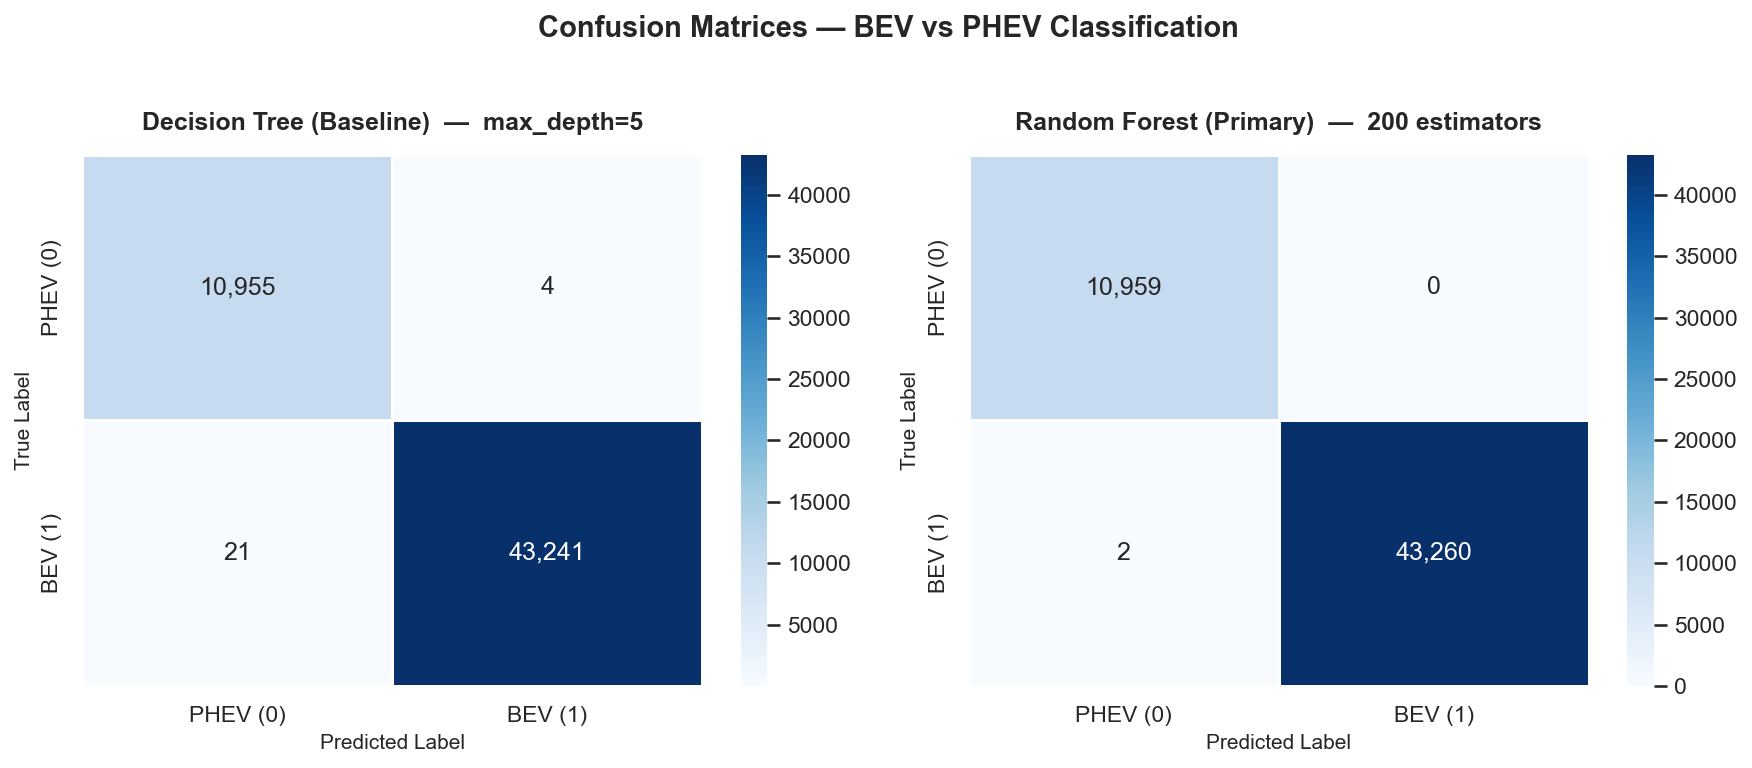

Saved: confusion_matrix_dt.png


In [7]:
# Plot confusion matrices for Decision Tree and Random Forest side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in zip(
    axes,
    [y_pred_dt, y_pred_rf],
    ["Decision Tree (Baseline)  —  max_depth=5",
     "Random Forest (Primary)  —  200 estimators"]
):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt=",", cmap="Blues", ax=ax,
        xticklabels=["PHEV (0)", "BEV (1)"],
        yticklabels=["PHEV (0)", "BEV (1)"],
        linewidths=0.5, linecolor="white"
    )
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    ax.set_xlabel("Predicted Label", fontsize=10)
    ax.set_ylabel("True Label", fontsize=10)

fig.suptitle("Confusion Matrices — BEV vs PHEV Classification", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("outputs/figures/confusion_matrix_dt.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: confusion_matrix_dt.png")

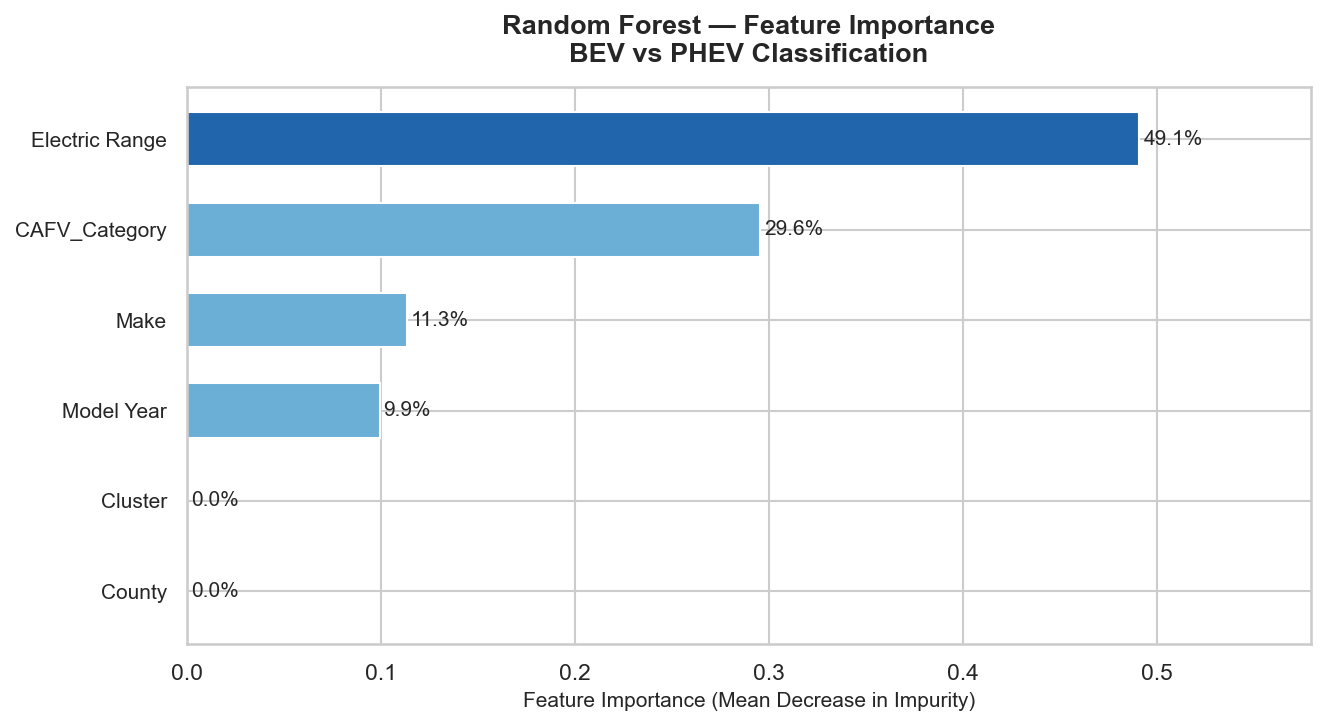

Saved: feature_importance.png

Feature importances:
  Electric Range     0.4909  (49.1%)
  CAFV_Category      0.2956  (29.6%)
  Make               0.1133  (11.3%)
  Model Year         0.0994  (9.9%)
  Cluster            0.0004  (0.0%)
  County             0.0003  (0.0%)


In [8]:
# Extract feature importances from the trained Random Forest
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2166ac" if v == importances.max() else "#6baed6" for v in importances.values]
bars = ax.barh(importances.index, importances.values, color=colors, edgecolor="white", height=0.6)

# Annotate each bar with its percentage value
for bar, val in zip(bars, importances.values):
    ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
            f"{val:.1%}", va="center", ha="left", fontsize=10)

ax.set_xlabel("Feature Importance (Mean Decrease in Impurity)", fontsize=10)
ax.set_title("Random Forest — Feature Importance\nBEV vs PHEV Classification", 
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlim(0, importances.max() * 1.18)
ax.tick_params(axis="y", labelsize=10)

plt.tight_layout()
plt.savefig("outputs/figures/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: feature_importance.png")
print("\nFeature importances:")
for feat, val in importances.sort_values(ascending=False).items():
    print(f"  {feat:<18} {val:.4f}  ({val:.1%})")

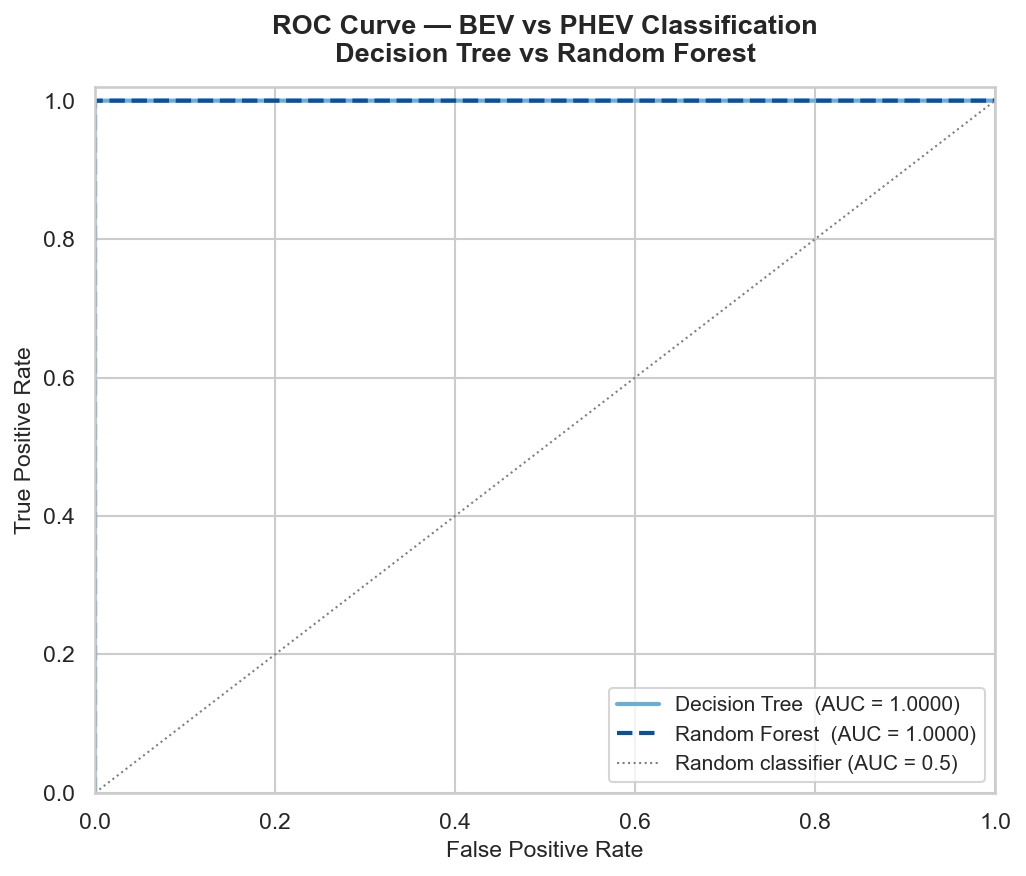

Saved: roc_curve.png


In [9]:
# Compute ROC curve data points for both models
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt.predict_proba(X_test)[:, 1])
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf.predict_proba(X_test)[:, 1])

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(fpr_dt, tpr_dt, color="#6baed6", lw=2,
        label=f"Decision Tree  (AUC = {roc_auc_score(y_test, dt.predict_proba(X_test)[:, 1]):.4f})")
ax.plot(fpr_rf, tpr_rf, color="#08519c", lw=2, linestyle="--",
        label=f"Random Forest  (AUC = {roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]):.4f})")
ax.plot([0, 1], [0, 1], color="grey", lw=1, linestyle=":", label="Random classifier (AUC = 0.5)")

ax.set_xlabel("False Positive Rate", fontsize=11)
ax.set_ylabel("True Positive Rate", fontsize=11)
ax.set_title("ROC Curve — BEV vs PHEV Classification\nDecision Tree vs Random Forest", 
             fontsize=13, fontweight="bold", pad=12)
ax.legend(fontsize=10, loc="lower right")
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])

plt.tight_layout()
plt.savefig("outputs/figures/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: roc_curve.png")

In [10]:
# Run 5-fold stratified cross-validation on the Random Forest to confirm generalization
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf, X, y, cv=cv, scoring="f1_weighted", n_jobs=-1)

print("5-Fold Cross-Validation — Random Forest (F1 Weighted)")
print("-" * 50)
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}:  {score:.4f}")
print(f"\n  Mean F1:  {cv_scores.mean():.4f}")
print(f"  Std Dev:  {cv_scores.std():.4f}")
print(f"\n  Interpretation: {'Low variance — model generalizes well.' if cv_scores.std() < 0.01 else 'Some variance detected across folds.'}")

5-Fold Cross-Validation — Random Forest (F1 Weighted)
--------------------------------------------------
  Fold 1:  0.9999
  Fold 2:  1.0000
  Fold 3:  1.0000
  Fold 4:  1.0000
  Fold 5:  1.0000

  Mean F1:  1.0000
  Std Dev:  0.0000

  Interpretation: Low variance — model generalizes well.


In [11]:
# Compile metrics from both models into a single results table and save
metrics_df = pd.DataFrame([dt_metrics, rf_metrics])
metrics_df["CV_Mean_F1"] = [None, cv_scores.mean()]
metrics_df["CV_Std_F1"]  = [None, cv_scores.std()]
metrics_df.to_csv("outputs/results/model_metrics.csv", index=False)

print("Saved: model_metrics.csv")
print("\n" + "=" * 55)
print("MODULE 06 — PREDICTIVE MODEL SUMMARY")
print("=" * 55)
print(f"\n  Dataset:        271,103 vehicle registrations")
print(f"  Features:       {len(features)} (Electric Range, CAFV_Category, Make, Model Year, County, Cluster)")
print(f"  Target:         EV_Type (BEV=1, PHEV=0)")
print(f"  Class balance:  79.8% BEV / 20.2% PHEV")
print(f"\n  --- Baseline: Decision Tree (max_depth=5) ---")
print(f"  Accuracy:   {dt_metrics['Accuracy']:.4f}")
print(f"  F1:         {dt_metrics['F1']:.4f}")
print(f"  ROC-AUC:    {dt_metrics['ROC-AUC']:.4f}")
print(f"\n  --- Primary: Random Forest (200 estimators) ---")
print(f"  Accuracy:   {rf_metrics['Accuracy']:.4f}")
print(f"  F1:         {rf_metrics['F1']:.4f}")
print(f"  ROC-AUC:    {rf_metrics['ROC-AUC']:.4f}")
print(f"  CV Mean F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
print(f"\n  --- Top Features ---")
for feat, val in pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False).items():
    print(f"  {feat:<18} {val:.1%}")
print("\n  Notebook complete. All figures and results saved.")

Saved: model_metrics.csv

MODULE 06 — PREDICTIVE MODEL SUMMARY

  Dataset:        271,103 vehicle registrations
  Features:       6 (Electric Range, CAFV_Category, Make, Model Year, County, Cluster)
  Target:         EV_Type (BEV=1, PHEV=0)
  Class balance:  79.8% BEV / 20.2% PHEV

  --- Baseline: Decision Tree (max_depth=5) ---
  Accuracy:   0.9995
  F1:         0.9995
  ROC-AUC:    1.0000

  --- Primary: Random Forest (200 estimators) ---
  Accuracy:   1.0000
  F1:         1.0000
  ROC-AUC:    1.0000
  CV Mean F1: 1.0000 (+/- 0.0000)

  --- Top Features ---
  Electric Range     49.1%
  CAFV_Category      29.6%
  Make               11.3%
  Model Year         9.9%
  Cluster            0.0%
  County             0.0%

  Notebook complete. All figures and results saved.
